<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/04_ejercicios_resueltos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 04 · Ejercicios resueltos de Aprendizaje por Refuerzo
**Machine Learning — Duoc UC**

Seis ejercicios para practicar **antes** del desafío. Cada ejercicio tiene:

1. **Enunciado** con la teoría mínima necesaria.
2. Una celda **«Tu solución»** para completar (donde dice `# TODO`).
3. Una celda **«Comprobar»** que revisa tu respuesta automáticamente.
4. Una celda **«Solución»**. En Colab aparece **oculta**: haz doble clic sobre ella (o en «Mostrar código») para verla. **Intenta primero.**

| # | Tema | Conceptos |
|---|---|---|
| 1 | Retorno y descuento | $G_t$, $\gamma$, recursión hacia atrás |
| 2 | Bandido de 10 brazos | exploración vs explotación, ε-greedy, UCB, regret, % acción óptima |
| 3 | MDP «Estudiante» a mano | ecuación de Bellman, evaluación de política, iteración de valor |
| 4 | Programación dinámica vs Q-learning | iteración de valor con modelo vs aprendizaje sin modelo |
| 5 | Encuentra los 3 bugs | depuración de un Q-learning |
| 6 | ¿Es significativa la diferencia? | IC95%, bootstrap, AUC con datos reales |

Esto es **tarea**, no la clase. Los ejemplos ya se vieron, y quedan resueltos, en los notebooks 01 (grilla), 02 (métricas) y 03 (técnicas). Aquí la celda «Tu solución» parte en blanco.

> Si un ejercicio no lo resuelves, ejecuta igual su celda de solución: los siguientes ejercicios no dependen de tu respuesta. Igual inténtalo antes de abrirla.

Para repasar mientras lo hacen: [StatQuest](https://www.youtube.com/watch?v=Z-T0iJEXiwM), [Serrano, Q-learning](https://www.youtube.com/watch?v=qhRNvCVVJaA) y el [libro de Sutton y Barto](http://incompleteideas.net/book/the-book-2nd.html).

In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /home/claude/rl_clase/notebooks | local


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rl_utils import CliffWalking, entrenar, evaluar_greedy, auc_normalizada

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

def ok(cond, msg_ok="✅ ¡Correcto!", msg_mal="❌ Todavía no. Revisa tu solución."):
    print(msg_ok if cond else msg_mal)

---
## Ejercicio 1 · Retorno y descuento

El **retorno** desde el tiempo $t$ es la suma descontada de las recompensas futuras:

$$G_t = r_{t+1} + \gamma r_{t+2} + \gamma^2 r_{t+3} + \dots = r_{t+1} + \gamma\, G_{t+1}$$

La segunda forma (recursiva) es la que usan todos los algoritmos: permite calcular **todos** los retornos de un episodio recorriéndolo **hacia atrás** en una sola pasada.

**a)** Implementa `retorno(recompensas, gamma)` que devuelve $G_0$.
**b)** Implementa `retornos_todos(recompensas, gamma)` que devuelve el arreglo $[G_0, G_1, \dots, G_{T-1}]$ usando la recursión hacia atrás.
**c)** Para `[-1, -1, -1, 10]`: ¿por qué $G_0$ con $\gamma=0{,}9$ es **menor** que con $\gamma=1$? ¿Qué le «enseña» $\gamma<1$ al agente?

In [3]:
# ✍️ Tu solución
def retorno(recompensas, gamma):
    # TODO
    return None

def retornos_todos(recompensas, gamma):
    # TODO: recorre de atrás hacia adelante: G = r + gamma * G
    return None

In [4]:
# 🔎 Comprobar
r = [-1, -1, -1, 10]
res_a = retorno(r, 0.9)
res_b = retornos_todos(r, 0.9)
if res_a is None or res_b is None:
    print("Aún no implementado.")
else:
    ok(np.isclose(res_a, 4.58) and np.isclose(retorno(r, 1.0), 7.0), "✅ a) correcto", "❌ a) revisa")
    ok(np.allclose(res_b, [4.58, 6.2, 8.0, 10.0]), "✅ b) correcto", "❌ b) revisa")

Aún no implementado.


In [5]:
#@title 💡 Solución ejercicio 1 (doble clic para ver el código)
def retorno(recompensas, gamma):
    return sum(gamma**k * r for k, r in enumerate(recompensas))

def retornos_todos(recompensas, gamma):
    G, out = 0.0, []
    for r in reversed(recompensas):
        G = r + gamma * G
        out.append(G)
    return np.array(out[::-1])

r = [-1, -1, -1, 10]
print("G0 con gamma=1.0:", retorno(r, 1.0))
print("G0 con gamma=0.9:", round(retorno(r, 0.9), 3))
print("Todos los G_t (gamma=0.9):", retornos_todos(r, 0.9).round(3))
print('''
c) Con gamma < 1, la recompensa +10 que llega en el paso 4 "vale" 10 * 0.9^3 = 7.29 hoy.
   El agente aprende a preferir recompensas TEMPRANAS: llegar antes a la meta vale más.
   gamma = 1 solo tiene sentido si los episodios siempre terminan (como aquí).
''')

G0 con gamma=1.0: 7.0
G0 con gamma=0.9: 4.58
Todos los G_t (gamma=0.9): [ 4.58  6.2   8.   10.  ]

c) Con gamma < 1, la recompensa +10 que llega en el paso 4 "vale" 10 * 0.9^3 = 7.29 hoy.
   El agente aprende a preferir recompensas TEMPRANAS: llegar antes a la meta vale más.
   gamma = 1 solo tiene sentido si los episodios siempre terminan (como aquí).



---
## Ejercicio 2 · Bandido de 10 brazos: exploración vs explotación

El problema de RL más simple: **un solo estado**, 10 acciones («brazos» de una máquina tragamonedas). Cada brazo $a$ entrega una recompensa $\sim \mathcal{N}(q_*(a), 1)$, con $q_*(a)$ desconocido. Objetivo: maximizar la recompensa total en 1.000 jugadas (Sutton & Barto, cap. 2).

El agente estima $Q(a)$ con el **promedio incremental** (el mismo truco que usamos en Monte Carlo):
$$Q(a) \leftarrow Q(a) + \frac{1}{N(a)}\big(r - Q(a)\big)$$

Estrategias:
- **Greedy** (ε = 0): siempre el brazo con mayor $Q$.
- **ε-greedy**: con probabilidad ε un brazo al azar.
- **UCB**: $\arg\max_a \; Q(a) + c\sqrt{\dfrac{\ln t}{N(a)}}$ → explora los brazos **inciertos** (pocos intentos), no al azar.

**Métricas** (las mismas ideas del notebook 02): recompensa media por paso, **% de veces que elige el brazo óptimo** y **regret acumulado** $\sum_t \big(q_*(a^*) - q_*(a_t)\big)$.

**Tarea:** completa `elegir_accion` (ε-greedy y UCB) y la actualización incremental.

In [6]:
# ✍️ Tu solución
def elegir_accion(Q, N, t, metodo, eps, c, rng):
    # metodo: "egreedy" o "ucb". Devuelve un entero 0..9
    # Pista UCB: los brazos con N == 0 se prueban primero.
    # TODO
    return None

def actualizar(Q, N, a, r):
    # TODO: N[a] += 1 y promedio incremental de Q[a]
    pass

In [7]:
# Simulador del experimento (ya está listo; usa tus funciones)
def bandido(metodo, eps=0.0, c=2.0, pasos=1000, corridas=200, seed=0):
    rng = np.random.default_rng(seed)
    recompensa = np.zeros((corridas, pasos)); optimo = np.zeros((corridas, pasos)); regret = np.zeros((corridas, pasos))
    for k in range(corridas):
        q_real = rng.normal(0, 1, 10); mejor = q_real.argmax()
        Q, N = np.zeros(10), np.zeros(10)
        for t in range(pasos):
            a = elegir_accion(Q, N, t + 1, metodo, eps, c, rng)
            r = rng.normal(q_real[a], 1)
            actualizar(Q, N, a, r)
            recompensa[k, t], optimo[k, t], regret[k, t] = r, a == mejor, q_real[mejor] - q_real[a]
    return recompensa, optimo, regret.cumsum(1)

In [8]:
# 🔎 Comprobar
_rng = np.random.default_rng(0)
if elegir_accion(np.zeros(10), np.zeros(10), 1, "egreedy", 0.1, 2, _rng) is None:
    print("Aún no implementado.")
else:
    _, opt, _ = bandido("egreedy", eps=0.1, corridas=50)
    _, opt_u, _ = bandido("ucb", c=2, corridas=50)
    ok(opt[:, -100:].mean() > 0.7, "✅ ε-greedy elige el brazo óptimo >70% al final", "❌ ε-greedy: revisa")
    ok(opt_u[:, -100:].mean() > 0.75, "✅ UCB funciona", "❌ UCB: revisa")

Aún no implementado.


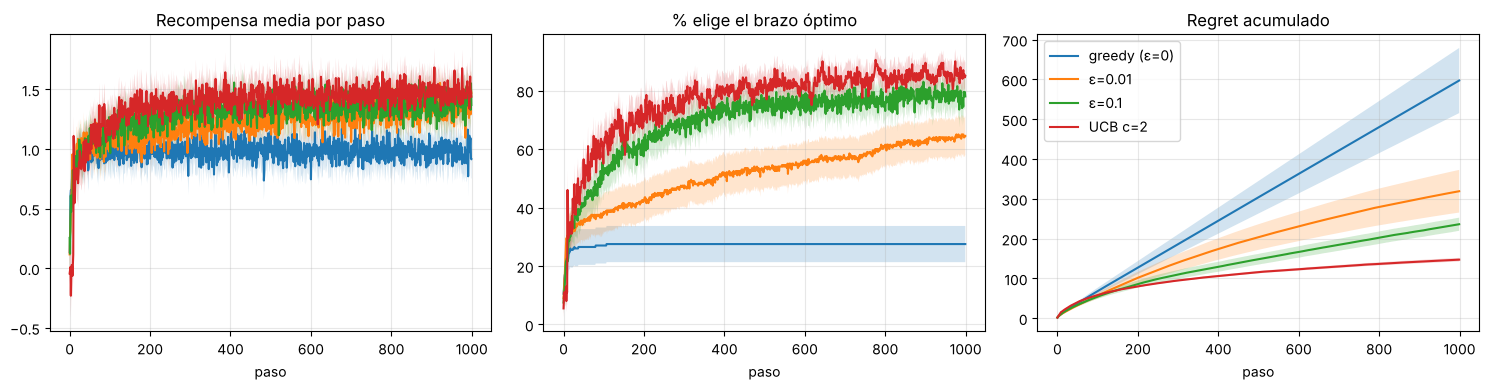


Lectura:
- Greedy se queda pegado en el primer brazo que "parece" bueno: elige el óptimo solo ~28% de las veces.
- ε = 0.1 aprende rápido (~78% óptimo al paso 1000), pero como explora al azar el 10% del tiempo nunca pasa de ~91%.
- ε = 0.01 aprende más lento (~64% al paso 1000); con muchos más pasos terminaría superando a ε = 0.1.
- UCB explora de forma DIRIGIDA (lo incierto): ~85% óptimo y el menor regret (~150 vs ~240 de ε = 0.1).
  Esta misma tensión exploración/explotación aparece en el desafío.



In [9]:
#@title 💡 Solución ejercicio 2 (doble clic para ver el código)
def elegir_accion(Q, N, t, metodo, eps, c, rng):
    if metodo == "ucb":
        if (N == 0).any():
            return int(np.flatnonzero(N == 0)[0])
        return int(np.argmax(Q + c * np.sqrt(np.log(t) / N)))
    if rng.random() < eps:
        return int(rng.integers(len(Q)))
    return int(rng.choice(np.flatnonzero(Q == Q.max())))   # desempate al azar

def actualizar(Q, N, a, r):
    N[a] += 1
    Q[a] += (r - Q[a]) / N[a]

configs = {"greedy (ε=0)": dict(metodo="egreedy", eps=0.0), "ε=0.01": dict(metodo="egreedy", eps=0.01),
           "ε=0.1": dict(metodo="egreedy", eps=0.1), "UCB c=2": dict(metodo="ucb", c=2.0)}
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for nombre, kw in configs.items():
    rec, opt, reg = bandido(**kw)
    for ax, M in zip(axs, [rec, opt * 100, reg]):
        m = M.mean(0); e = 1.96 * M.std(0) / np.sqrt(len(M))
        ax.plot(m, label=nombre); ax.fill_between(range(len(m)), m - e, m + e, alpha=0.2)
axs[0].set_title("Recompensa media por paso"); axs[1].set_title("% elige el brazo óptimo"); axs[2].set_title("Regret acumulado")
for ax in axs: ax.set_xlabel("paso")
axs[2].legend(); plt.tight_layout(); plt.show()
print('''
Lectura:
- Greedy se queda pegado en el primer brazo que "parece" bueno: elige el óptimo solo ~28% de las veces.
- ε = 0.1 aprende rápido (~78% óptimo al paso 1000), pero como explora al azar el 10% del tiempo nunca pasa de ~91%.
- ε = 0.01 aprende más lento (~64% al paso 1000); con muchos más pasos terminaría superando a ε = 0.1.
- UCB explora de forma DIRIGIDA (lo incierto): ~85% óptimo y el menor regret (~150 vs ~240 de ε = 0.1).
  Esta misma tensión exploración/explotación aparece en el desafío.
''')

---
## Ejercicio 3 · MDP «Estudiante» resuelto con Bellman

Un estudiante puede estar **Descansado (D)** o **Cansado (C)**. Cada día elige **estudiar** o **descansar**. Aprobar (**A**) es terminal.

| Estado | Acción | Resultado | Recompensa |
|---|---|---|---|
| D | estudiar | 80% → A · 20% → C | +10 si aprueba, −2 si queda cansado |
| D | descansar | 100% → D | −1 |
| C | estudiar | 30% → A · 70% → C | +10 si aprueba, −2 si sigue cansado |
| C | descansar | 100% → D | −1 |

Con $\gamma = 0{,}9$:

**a) Evaluación de política.** Para la política «siempre estudiar», la ecuación de Bellman da un sistema **lineal**:
$$V(D) = 0{,}8\cdot 10 + 0{,}2\,(-2 + \gamma V(C)) \qquad V(C) = 0{,}3\cdot 10 + 0{,}7\,(-2 + \gamma V(C))$$
Resuélvelo (a mano o con `np.linalg.solve`).

**b) Iteración de valor.** Repite $V(s) \leftarrow \max_a \sum_{s'} p(s'|s,a)\,[r + \gamma V(s')]$ hasta converger. ¿Cuál es la política óptima? ¿Siempre conviene estudiar?

In [10]:
# ✍️ Tu solución
gamma = 0.9
V_estudiar = None   # TODO a): np.array([V(D), V(C)])
V_optimo = None     # TODO b): np.array([V*(D), V*(C)])
politica_optima = None  # TODO b): dict, ej. {"D": "estudiar", "C": "..."}

In [11]:
# 🔎 Comprobar
if V_estudiar is None or V_optimo is None or politica_optima is None:
    print("Aún no implementado.")
else:
    ok(np.allclose(V_estudiar, [8.378, 4.324], atol=1e-2), "✅ a) correcto", "❌ a) revisa el sistema lineal")
    ok(np.allclose(V_optimo, [8.854, 6.969], atol=1e-2), "✅ b) valores óptimos correctos", "❌ b) revisa la iteración de valor")
    ok(politica_optima == {"D": "estudiar", "C": "descansar"}, "✅ b) política correcta", "❌ b) revisa la política")

Aún no implementado.


In [12]:
#@title 💡 Solución ejercicio 3 (doble clic para ver el código)
gamma = 0.9
# a) Evaluación de política "siempre estudiar": (I - gamma*P) V = R
#    V(D) - 0.2*gamma*V(C) = 0.8*10 + 0.2*(-2)
#    V(C) - 0.7*gamma*V(C) = 0.3*10 + 0.7*(-2)
A = np.array([[1, -0.2 * gamma], [0, 1 - 0.7 * gamma]])
b = np.array([0.8 * 10 + 0.2 * -2, 0.3 * 10 + 0.7 * -2])
V_estudiar = np.linalg.solve(A, b)
print("a) V^estudiar: V(D) = %.3f   V(C) = %.3f" % tuple(V_estudiar))

# b) Iteración de valor. Modelo: (estado, acción) -> lista de (prob, siguiente, recompensa); None = terminal
D, Cn = 0, 1
modelo = {(D, "estudiar"): [(0.8, None, 10), (0.2, Cn, -2)], (D, "descansar"): [(1.0, D, -1)],
          (Cn, "estudiar"): [(0.3, None, 10), (0.7, Cn, -2)], (Cn, "descansar"): [(1.0, D, -1)]}
acciones = ["estudiar", "descansar"]
V = np.zeros(2)
for it in range(1000):
    Q = {(s, a): sum(p * (r + (0 if s2 is None else gamma * V[s2])) for p, s2, r in modelo[(s, a)])
         for s in (D, Cn) for a in acciones}
    V_nuevo = np.array([max(Q[(s, a)] for a in acciones) for s in (D, Cn)])
    if np.abs(V_nuevo - V).max() < 1e-10:
        break
    V = V_nuevo
V_optimo = V
politica_optima = {n: max(acciones, key=lambda a: Q[(s, a)]) for n, s in [("D", D), ("C", Cn)]}
print(f"b) convergió en {it} iteraciones: V*(D) = {V[0]:.3f}   V*(C) = {V[1]:.3f}")
print("   Q*(C, estudiar) = %.3f   Q*(C, descansar) = %.3f" % (Q[(Cn, 'estudiar')], Q[(Cn, 'descansar')]))
print("   Política óptima:", politica_optima)
print('''
Interpretación: estando cansado conviene DESCANSAR (-1 un día) para pasar a Descansado, donde estudiar
tiene 80% de éxito. "Siempre estudiar" vale 4.32 desde Cansado; la política óptima vale 6.97.
Esto es exactamente lo que Q-learning aprende SIN conocer las probabilidades: probando.
''')

a) V^estudiar: V(D) = 8.378   V(C) = 4.324
b) convergió en 28 iteraciones: V*(D) = 8.854   V*(C) = 6.969
   Q*(C, estudiar) = 5.990   Q*(C, descansar) = 6.969
   Política óptima: {'D': 'estudiar', 'C': 'descansar'}

Interpretación: estando cansado conviene DESCANSAR (-1 un día) para pasar a Descansado, donde estudiar
tiene 80% de éxito. "Siempre estudiar" vale 4.32 desde Cansado; la política óptima vale 6.97.
Esto es exactamente lo que Q-learning aprende SIN conocer las probabilidades: probando.



---
## Ejercicio 4 · Con modelo vs sin modelo: iteración de valor y Q-learning en CliffWalking

Si **conocemos** el modelo del entorno (qué pasa al hacer cada acción), podemos calcular $Q^*$ directamente con **programación dinámica** (iteración de valor), sin interactuar. Q-learning llega a lo mismo **sin modelo**, a costa de muchas interacciones.

**Tarea:** usando el modelo determinista de CliffWalking (ya implementado en `modelo_cliff`), implementa iteración de valor sobre $Q$:
$$Q(s,a) \leftarrow r + \gamma\,\max_{a'} Q(s',a') \quad (\text{0 si } s' \text{ es la meta})$$
y compara con la tabla que aprende Q-learning en 500 episodios. Pregunta: ¿por qué en los estados **lejos del camino óptimo** las dos tablas difieren más?

In [13]:
# Modelo determinista de CliffWalking (copia de la dinámica de rl_utils.CliffWalking)
def modelo_cliff(s, a):
    f, c = divmod(s, 12)
    df, dc = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}[a]
    f, c = min(max(f + df, 0), 3), min(max(c + dc, 0), 11)
    if f == 3 and 1 <= c <= 10:
        return 36, -100.0, False      # cae: vuelve al inicio
    return f * 12 + c, -1.0, (f, c) == (3, 11)

# ✍️ Tu solución
def iteracion_valor_cliff(gamma=1.0, tol=1e-9):
    Q = np.zeros((48, 4))
    # TODO: repetir el barrido sobre todos los (s, a) hasta que el cambio máximo < tol
    return None

In [14]:
# 🔎 Comprobar
Q_dp = iteracion_valor_cliff()
if Q_dp is None:
    print("Aún no implementado.")
else:
    ok(np.isclose(Q_dp[36].max(), -13), "✅ V*(inicio) = -13 (camino de 13 pasos)", f"❌ V*(inicio) = {Q_dp[36].max()}")

Aún no implementado.


Iteración de valor: 16 barridos, 0 interacciones con el entorno


Q-learning: 11,380 interacciones con el entorno
V*(inicio): DP = -13.0 | Q-learning = -13.0


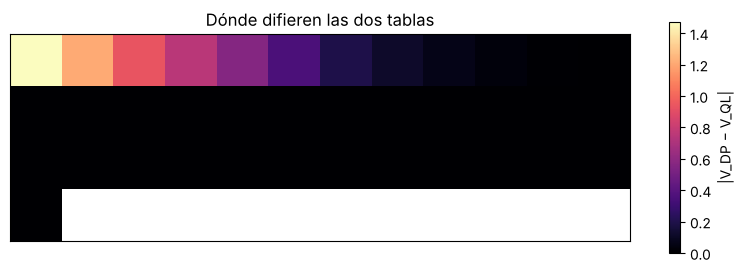


Los estados del camino que el agente recorre seguido quedan bien estimados; los estados poco visitados
(lejos del camino) tienen menos actualizaciones y por eso sus valores aún no convergen.
Q-learning solo garantiza buenos valores DONDE EXPLORA lo suficiente.



In [15]:
#@title 💡 Solución ejercicio 4 (doble clic para ver el código)
def iteracion_valor_cliff(gamma=1.0, tol=1e-9):
    Q = np.zeros((48, 4))
    for barrido in range(1000):
        delta = 0.0
        for s in range(48):
            if s == 47:          # la meta es terminal
                continue
            for a in range(4):
                s2, r, meta = modelo_cliff(s, a)
                nuevo = r + (0 if meta else gamma * Q[s2].max())
                delta = max(delta, abs(nuevo - Q[s, a]))
                Q[s, a] = nuevo
        if delta < tol:
            break
    print(f"Iteración de valor: {barrido + 1} barridos, 0 interacciones con el entorno")
    return Q

Q_dp = iteracion_valor_cliff()
Q_ql, log = entrenar("q_learning", n_episodios=500, seed=0)
print(f"Q-learning: {log.largo.sum():,} interacciones con el entorno")
print("V*(inicio): DP =", Q_dp[36].max(), "| Q-learning =", round(Q_ql[36].max(), 2))

dif = np.abs(Q_dp.max(1) - Q_ql.max(1)).reshape(4, 12); dif[3, 1:] = np.nan
plt.figure(figsize=(10, 3)); plt.imshow(dif, cmap="magma"); plt.colorbar(label="|V_DP − V_QL|")
plt.title("Dónde difieren las dos tablas"); plt.xticks([]); plt.yticks([]); plt.show()
print('''
Los estados del camino que el agente recorre seguido quedan bien estimados; los estados poco visitados
(lejos del camino) tienen menos actualizaciones y por eso sus valores aún no convergen.
Q-learning solo garantiza buenos valores DONDE EXPLORA lo suficiente.
''')

---
## Ejercicio 5 · Encuentra los 3 bugs

Este Q-learning «casi» funciona: corre sin errores, pero no aprende. Tiene **3 bugs** (todos son errores reales y frecuentes, también en código generado por IA). Encuéntralos, corrígelos y verifica que la política greedy logre el retorno óptimo **−13**.

Estrategia de depuración sugerida: imprime el retorno por episodio, revisa la tabla Q de un estado después de unas pocas actualizaciones y compárala con la ecuación de Q-learning.

In [16]:
def q_learning_con_bugs(n_episodios=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    env = CliffWalking(seed=seed)
    Q = np.zeros((48, 4))
    for ep in range(n_episodios):
        s, done = env.reset(), False
        while not done:
            a = int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, done, info = env.step(a)
            objetivo = r + (0 if info["llego"] else gamma * Q[s2].min())
            Q[s, a] = alpha * (objetivo - Q[s, a])
    return Q

print("Retorno greedy con bugs:", evaluar_greedy(q_learning_con_bugs()).mean())

Retorno greedy con bugs: -200.0


In [17]:
# ✍️ Tu solución: copia la función de arriba, corrígela y llámala q_learning_corregido
def q_learning_corregido(n_episodios=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    # TODO
    return None

In [18]:
# 🔎 Comprobar
Q_fix = q_learning_corregido()
if Q_fix is None:
    print("Aún no implementado.")
else:
    ok(evaluar_greedy(Q_fix).mean() == -13, "✅ ¡Aprende el camino óptimo!", "❌ Todavía hay bugs")

Aún no implementado.


In [19]:
#@title 💡 Solución ejercicio 5 (doble clic para ver el código)
def q_learning_corregido(n_episodios=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    env = CliffWalking(seed=seed)
    Q = np.zeros((48, 4))
    for ep in range(n_episodios):
        s, done = env.reset(), False
        while not done:
            a = int(rng.integers(4)) if rng.random() < eps else int(np.argmax(Q[s]))
            s2, r, done, info = env.step(a)
            objetivo = r + (0 if info["llego"] else gamma * Q[s2].max())   # BUG 1: era .min()
            Q[s, a] += alpha * (objetivo - Q[s, a])                         # BUG 2: era "=" en vez de "+="
            s = s2                                                          # BUG 3: faltaba avanzar el estado
    return Q

print("Retorno greedy corregido:", evaluar_greedy(q_learning_corregido()).mean())
print('''
BUG 1 — .min(): el objetivo debe usar la MEJOR acción siguiente (optimismo de Q-learning), no la peor.
BUG 2 — "=": así Q olvida todo lo anterior; la regla TD corrige el valor actual un paso alpha hacia el objetivo.
BUG 3 — sin "s = s2": el agente siempre actualiza el estado inicial y elige acciones con la Q del estado equivocado.
Lección: código que "corre" no es código que "aprende". Siempre comparar contra un resultado conocido.
''')

Retorno greedy corregido: -13.0

BUG 1 — .min(): el objetivo debe usar la MEJOR acción siguiente (optimismo de Q-learning), no la peor.
BUG 2 — "=": así Q olvida todo lo anterior; la regla TD corrige el valor actual un paso alpha hacia el objetivo.
BUG 3 — sin "s = s2": el agente siempre actualiza el estado inicial y elige acciones con la Q del estado equivocado.
Lección: código que "corre" no es código que "aprende". Siempre comparar contra un resultado conocido.



---
## Ejercicio 6 · ¿Q-learning es mejor que SARSA? Que respondan los datos

Usa `runs_cliffwalking.csv` (10 semillas por algoritmo, ε con decaimiento).

**a)** Para `q_learning` y `sarsa`, calcula por semilla el retorno medio de los **últimos 50 episodios**. Reporta media ± IC95% de cada algoritmo.
**b)** Calcula un **IC95% bootstrap** de la diferencia de medias (q_learning − sarsa): remuestrea con reemplazo las semillas de cada algoritmo 10.000 veces.
**c)** Calcula la **AUC normalizada** (entre −200 y −13) de cada semilla y compara.
**d)** Conclusión: ¿puedes afirmar que uno es mejor? ¿Depende de la métrica?

In [20]:
runs = pd.read_csv("../data/runs_cliffwalking.csv")

# ✍️ Tu solución
final = None      # TODO a): Series o dict {algoritmo: array de 10 valores (uno por semilla)}
ic_dif = None     # TODO b): tupla (limite_inferior, limite_superior)
auc = None        # TODO c): dict {algoritmo: array de 10 AUC}

In [21]:
# 🔎 Comprobar
if final is None or ic_dif is None or auc is None:
    print("Aún no implementado.")
else:
    ok(len(final["q_learning"]) == 10 and abs(np.mean(final["sarsa"]) - (-17.2)) < 0.2, "✅ a) correcto", "❌ a) revisa")
    ok(ic_dif[0] < 0 < ic_dif[1], "✅ b) el IC de la diferencia contiene 0", "❌ b) revisa el bootstrap")
    ok(np.mean(auc["sarsa"]) > np.mean(auc["q_learning"]), "✅ c) correcto", "❌ c) revisa")

Aún no implementado.


In [22]:
#@title 💡 Solución ejercicio 6 (doble clic para ver el código)
runs = pd.read_csv("../data/runs_cliffwalking.csv")
sub = runs[runs.algoritmo.isin(["q_learning", "sarsa"])]

# a)
final = {alg: g.groupby("seed").apply(lambda x: x.sort_values("episodio").retorno.tail(50).mean(), include_groups=False).to_numpy()
         for alg, g in sub.groupby("algoritmo")}
for alg, x in final.items():
    print(f"a) {alg:10s} retorno final = {x.mean():6.2f} ± {1.96 * x.std(ddof=1) / np.sqrt(len(x)):.2f}")

# b) bootstrap de la diferencia de medias
rng = np.random.default_rng(0)
q, s = final["q_learning"], final["sarsa"]
difs = [rng.choice(q, len(q)).mean() - rng.choice(s, len(s)).mean() for _ in range(10_000)]
ic_dif = tuple(np.percentile(difs, [2.5, 97.5]))
print(f"b) diferencia q_learning − sarsa = {q.mean() - s.mean():.2f}, IC95% bootstrap = [{ic_dif[0]:.2f}, {ic_dif[1]:.2f}]")

# c) AUC normalizada
auc = {alg: np.array([auc_normalizada(gs.sort_values("episodio").retorno, -200, -13) for _, gs in g.groupby("seed")])
       for alg, g in sub.groupby("algoritmo")}
for alg, x in auc.items():
    print(f"c) {alg:10s} AUC = {x.mean():.3f} ± {1.96 * x.std(ddof=1) / np.sqrt(len(x)):.3f}")

print('''
d) En retorno FINAL no podemos afirmar diferencia: el IC de la diferencia contiene 0 (con 10 semillas).
   En AUC (eficiencia durante el aprendizaje) SARSA es claramente mejor: aprende de forma más segura
   y cae menos al acantilado mientras explora.
   → "¿Cuál es mejor?" no tiene sentido sin decir QUÉ métrica importa para el problema.
''')

a) q_learning retorno final = -16.73 ± 1.77
a) sarsa      retorno final = -17.21 ± 0.05


b) diferencia q_learning − sarsa = 0.48, IC95% bootstrap = [-1.22, 2.10]
c) q_learning AUC = 0.774 ± 0.008
c) sarsa      AUC = 0.871 ± 0.014

d) En retorno FINAL no podemos afirmar diferencia: el IC de la diferencia contiene 0 (con 10 semillas).
   En AUC (eficiencia durante el aprendizaje) SARSA es claramente mejor: aprende de forma más segura
   y cae menos al acantilado mientras explora.
   → "¿Cuál es mejor?" no tiene sentido sin decir QUÉ métrica importa para el problema.



---
## Para seguir
- Sutton & Barto, *Reinforcement Learning: An Introduction* (2ª ed.), caps. 2 (bandidos), 3–4 (MDP y programación dinámica), 5 (Monte Carlo) y 6 (TD: Q-learning y SARSA). Gratis en [incompleteideas.net](http://incompleteideas.net/book/the-book-2nd.html).
- Ahora sí: al **notebook 05** (desafío).